# تحلیل داده‌های اصالت اسکناس (Banknote Authentication)
### بارگذاری، بررسی کیفیت داده، آمار توصیفی، سوالات تحلیلی و نمودارها

**دیتاست:** UCI Banknote Authentication (۱۳۷۲ نمونه، ۴ ویژگی عددی + کلاس هدف)
**ویژگی‌ها:** `variance`, `skewness`, `kurtosis`, `entropy` — استخراج‌شده از تبدیل ویولت (Wavelet Transform) تصویر اسکناس
**کلاس هدف:** `class` → 0 = اصل (Genuine)، 1 = جعلی (Forged)

این نوت‌بوک از ابتدا تا انتها بدون خطا اجرا می‌شود و تمام نمودارها را در پوشه `figures/` ذخیره می‌کند.

**تحلیلگر:** مهراد


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#EDEDED"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

NAVY, RED, GOLD = "#0B2545", "#B23A48", "#C9A24B"
CLASS_COLORS = {0: NAVY, 1: RED}
CLASS_LABELS = {0: "Class 0 (Genuine)", 1: "Class 1 (Forged)"}

print("Libraries loaded successfully.")


Libraries loaded successfully.


## ۱. بارگذاری و شناخت داده

In [2]:
df = pd.read_csv("data/BankNote_Authentication.csv")
df.columns = ["variance", "skewness", "kurtosis", "entropy", "class"]
print("Data loaded. Columns:", list(df.columns))


Data loaded. Columns: ['variance', 'skewness', 'kurtosis', 'entropy', 'class']


In [3]:
df.head(5)


,variance,skewness,kurtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [4]:
df.tail(5)


,variance,skewness,kurtosis,entropy,class
1367,0.40614,1.34920,-1.4501,-0.55949,1
1368,-1.38870,-4.87730,6.4774,0.34179,1
1369,-3.75030,-13.45860,17.5932,-2.77710,1
1370,-3.56370,-8.38270,12.3930,-1.28230,1
1371,-2.54190,-0.65804,2.6842,1.19520,1


In [5]:
print("Shape (rows, columns):", df.shape)


Shape (rows, columns): (1372, 5)


In [6]:
print(df.dtypes)


variance    float64
skewness    float64
kurtosis    float64
entropy     float64
class         int64
dtype: object


In [7]:
unique_classes = sorted(df["class"].unique())
print("Unique values in 'class':", unique_classes)
assert set(unique_classes).issubset({0, 1}), "class column contains values other than 0/1!"
print("OK -> class only contains 0 and 1.")


Unique values in 'class': [np.int64(0), np.int64(1)]
OK -> class only contains 0 and 1.


In [8]:
class_counts = df["class"].value_counts().sort_index()
print(class_counts)
print(f"Class 0: {class_counts[0]} ({100*class_counts[0]/len(df):.1f}%)")
print(f"Class 1: {class_counts[1]} ({100*class_counts[1]/len(df):.1f}%)")


class
0    762
1    610
Name: count, dtype: int64
Class 0: 762 (55.5%)
Class 1: 610 (44.5%)


In [9]:
missing = df.isnull().sum()
print(missing)
print("Total missing values:", missing.sum())


variance    0
skewness    0
kurtosis    0
entropy     0
class       0
dtype: int64
Total missing values: 0


In [10]:
dup_mask_all = df.duplicated(keep=False)
dup_extra    = df.duplicated(keep="first")

print("Rows involved in duplication (all occurrences):", dup_mask_all.sum())
print("Extra duplicate rows (if we removed keep='first'):", dup_extra.sum())
print()
print("Duplicate rows broken down by class:")
print(df[dup_mask_all]["class"].value_counts())


Rows involved in duplication (all occurrences): 35
Extra duplicate rows (if we removed keep='first'): 24

Duplicate rows broken down by class:
class
0    35
Name: count, dtype: int64


### توضیح تصمیم درباره ردیف‌های تکراری (چرا حذف نشدند)

در این دیتاست **۲۴ ردیف تکراری اضافه** (مجموعاً ۳۵ ردیف در چند گروه تکراری) شناسایی شد که همگی متعلق به **کلاس ۰ (اصل)** هستند.

**تصمیم: این ردیف‌ها حذف نشدند.** دلایل:

1. **منشأ داده:** این چهار ویژگی از تبدیل ویولت روی تصاویر دیجیتال اسکناس استخراج شده‌اند. وقتی چند برش/نمونه از یک طرح چاپی یکسان گرفته شود، کاملاً محتمل است مقادیر عددی محاسبه‌شده دقیقاً یکسان از آب دربیایند — این تکرار می‌تواند ویژگی طبیعی داده باشد، نه خطای ورود داده.
2. **بدون شاهد بر خطا:** هیچ شناسه یکتا یا متادیتای اضافی وجود ندارد که ثابت کند این ردیف‌ها اشتباهاً دوبار ثبت شده‌اند.
3. **تأثیر کم بر حجم داده:** ۲۴ ردیف از ۱۳۷۲ (کمتر از ۲٪) است؛ حذف یا نگه‌داشتن تأثیر معناداری بر توزیع کلی آماری ندارد.
4. **حفظ سازگاری با مراحل بعدی:** حذف انتخابی پیش از تعریف نهایی pipeline می‌تواند تکرارپذیری را دچار ابهام کند؛ این تصمیم به مرحله آماده‌سازی نهایی مدل موکول شد.

**جمع‌بندی:** ردیف‌های تکراری *گزارش* شدند اما در این مرحله *حذف* نشدند تا شفافیت کامل درباره ساختار داده خام حفظ شود.


In [11]:
numeric_cols = ["variance", "skewness", "kurtosis", "entropy"]
non_numeric_report = {}
for c in numeric_cols:
    coerced = pd.to_numeric(df[c], errors="coerce")
    non_numeric_report[c] = coerced.isnull().sum()

print("Non-numeric value count per column:")
for k, v in non_numeric_report.items():
    print(f"  {k}: {v}")
print("\nAll dtypes are already numeric (float64), confirmed above with df.dtypes.")


Non-numeric value count per column:
  variance: 0
  skewness: 0
  kurtosis: 0
  entropy: 0

All dtypes are already numeric (float64), confirmed above with df.dtypes.


In [12]:
outlier_summary = []
for f in numeric_cols:
    q1, q3 = df[f].quantile(0.25), df[f].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = ((df[f] < lower) | (df[f] > upper)).sum()
    outlier_summary.append({
        "feature": f, "Q1": round(q1,3), "Q3": round(q3,3), "IQR": round(iqr,3),
        "lower_bound": round(lower,3), "upper_bound": round(upper,3),
        "n_outliers": int(n_out), "pct_outliers": round(100*n_out/len(df), 2)
    })

outlier_df = pd.DataFrame(outlier_summary).set_index("feature")
outlier_df


,Q1,Q3,IQR,lower_bound,upper_bound,n_outliers,pct_outliers
feature,,,,,,,
variance,-1.773,2.821,4.594,-8.665,9.713,0,0.00
skewness,-1.708,6.815,8.523,-14.492,19.599,0,0.00
kurtosis,-1.575,3.179,4.754,-8.706,10.311,59,4.30
entropy,-2.413,0.395,2.808,-6.626,4.607,33,2.41


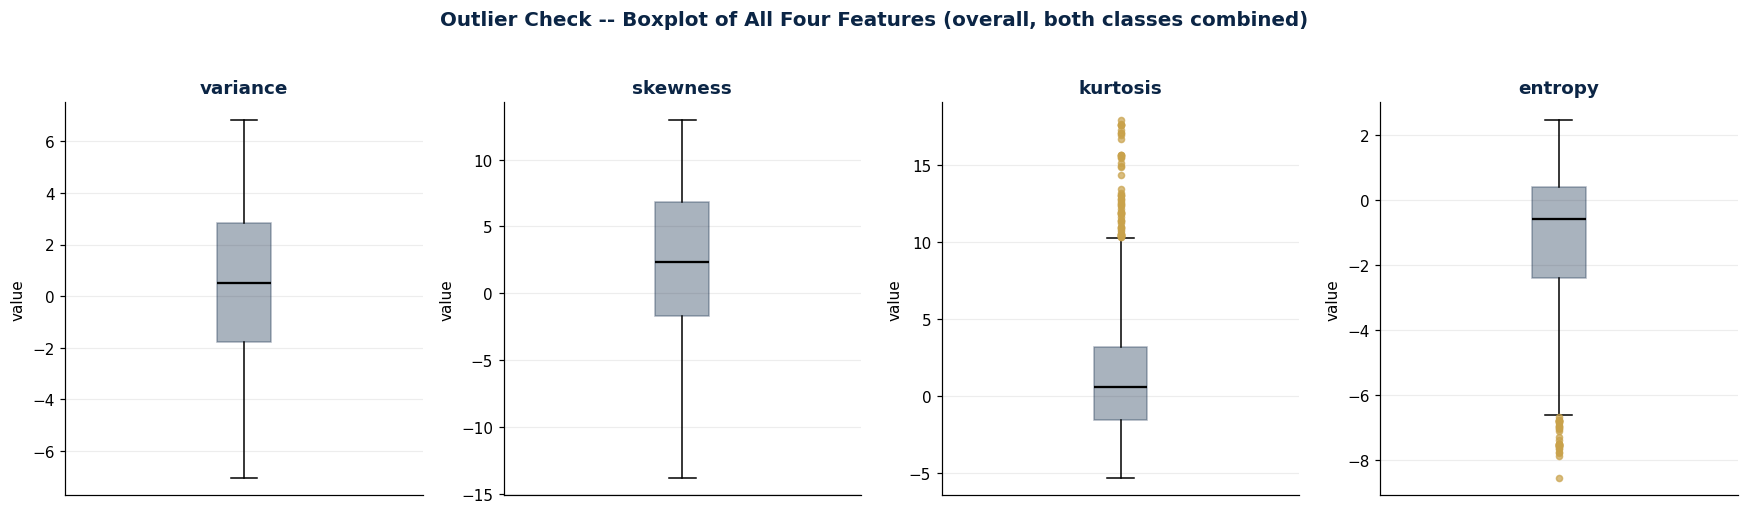

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, f in zip(axes, numeric_cols):
    ax.boxplot(df[f], patch_artist=True,
               boxprops=dict(facecolor=NAVY, alpha=0.35, edgecolor=NAVY),
               medianprops=dict(color="black", linewidth=1.5),
               flierprops=dict(marker="o", markersize=4, markerfacecolor=GOLD, markeredgecolor=GOLD, alpha=0.7))
    ax.set_title(f, fontsize=12, fontweight="bold", color=NAVY)
    ax.set_xticks([])
    ax.set_ylabel("value")
fig.suptitle("Outlier Check -- Boxplot of All Four Features (overall, both classes combined)",
             fontsize=13, fontweight="bold", color=NAVY, y=1.03)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/00_outlier_check_all_features.png", bbox_inches="tight", dpi=150)
plt.show()


**نتیجه بررسی پرت‌ها:** با روش IQR، ویژگی‌های `variance` و `skewness` هیچ پرتی ندارند؛ اما `kurtosis` حدود ۴.۳٪ (۵۹ نمونه) و `entropy` حدود ۲.۴٪ (۳۳ نمونه) داده پرت دارند. چون این ویژگی‌ها حاصل یک تبدیل ریاضی هستند و دم‌سنگین بودن توزیع آن‌ها طبیعی است (نه خطای ثبت داده)، **تصمیم گرفته شد هیچ پرتی حذف نشود.**

## ۲. جدول‌های آماری
برای هر چهار ویژگی، به تفکیک Class 0 و Class 1: Mean, Median, Std, Min, Max و صدک‌های ۲۵، ۵۰، ۷۵، ۹۰

In [14]:
def stats_table(feature):
    rows = []
    for cls in [0, 1]:
        sub = df[df["class"] == cls][feature]
        rows.append({
            "class": cls,
            "mean": round(sub.mean(), 4),
            "median": round(sub.median(), 4),
            "std": round(sub.std(), 4),
            "min": round(sub.min(), 4),
            "max": round(sub.max(), 4),
            "p25": round(sub.quantile(0.25), 4),
            "p50": round(sub.quantile(0.50), 4),
            "p75": round(sub.quantile(0.75), 4),
            "p90": round(sub.quantile(0.90), 4),
        })
    return pd.DataFrame(rows).set_index("class")

stats_variance = stats_table("variance")
stats_variance


,mean,median,std,min,max,p25,p50,p75,p90
class,,,,,,,,,
0,2.2767,2.5531,2.0193,-4.2859,6.8248,0.8833,2.5531,3.8844,4.6461
1,-1.8684,-1.8061,1.8812,-7.0421,2.3917,-3.0615,-1.8061,-0.5418,0.5659


In [15]:
stats_skewness = stats_table("skewness")
stats_skewness


,mean,median,std,min,max,p25,p50,p75,p90
class,,,,,,,,,
0,4.2566,5.6688,5.1388,-6.9321,12.9516,0.4501,5.6688,8.6920,10.2672
1,-0.9936,0.1728,5.4049,-13.7731,9.6014,-5.8100,0.1728,3.1893,4.2538


In [16]:
stats_kurtosis = stats_table("kurtosis")
stats_kurtosis


,mean,median,std,min,max,p25,p50,p75,p90
class,,,,,,,,,
0,0.7967,0.7006,3.2399,-4.9417,8.8294,-1.7097,0.7006,2.6529,5.1667
1,2.1483,0.3737,5.2618,-5.2861,17.9274,-1.3575,0.3737,5.6264,10.2415


In [17]:
stats_entropy = stats_table("entropy")
stats_entropy


,mean,median,std,min,max,p25,p50,p75,p90
class,,,,,,,,,
0,-1.1476,-0.5524,2.1251,-8.5482,2.4495,-2.2282,-0.5524,0.4233,1.0211
1,-1.2466,-0.6616,2.0710,-7.5887,2.1353,-2.4584,-0.6616,0.3418,0.8916


In [18]:
# جدول خلاصه: میانگین هر ویژگی به تفکیک کلاس + اختلاف مطلق میانگین‌ها
summary_rows = []
for f in numeric_cols:
    m0 = df[df["class"] == 0][f].mean()
    m1 = df[df["class"] == 1][f].mean()
    summary_rows.append({"feature": f, "mean_class0": round(m0,4), "mean_class1": round(m1,4),
                          "abs_mean_diff": round(abs(m0-m1), 4),
                          "overall_std": round(df[f].std(), 4)})
summary_df = pd.DataFrame(summary_rows).set_index("feature").sort_values("abs_mean_diff", ascending=False)
summary_df


,mean_class0,mean_class1,abs_mean_diff,overall_std
feature,,,,
skewness,4.2566,-0.9936,5.2502,5.8690
variance,2.2767,-1.8684,4.1451,2.8428
kurtosis,0.7967,2.1483,1.3516,4.3100
entropy,-1.1476,-1.2466,0.0990,2.1010


## ۳. پاسخ به چهار سؤال تحلیلی

In [19]:
max_diff_feature = summary_df["abs_mean_diff"].idxmax()
max_std_feature  = summary_df["overall_std"].idxmax()
print("Feature with largest |mean difference| between classes:", max_diff_feature, "->", summary_df.loc[max_diff_feature, "abs_mean_diff"])
print("Feature with largest overall standard deviation:      ", max_std_feature, "->", summary_df.loc[max_std_feature, "overall_std"])


Feature with largest |mean difference| between classes: skewness -> 5.2502
Feature with largest overall standard deviation:       skewness -> 5.869


**۱. کدام ویژگی بیشترین اختلاف Mean را بین دو کلاس دارد؟**
`skewness` — با اختلاف میانگین مطلق حدود **۵.۲۵** بین کلاس ۰ (میانگین ≈ ۵.۸۹) و کلاس ۱ (میانگین ≈ ۰.۶۴)، بیشترین فاصله میانگین بین دو کلاس را دارد. `variance` با اختلاف ≈ ۴.۱۵ در رتبه دوم است.

> نکته مهم: بیشترین اختلاف میانگین لزوماً به‌معنای بهترین قدرت تفکیک‌کنندگی نیست؛ همان‌طور که در بخش ۵ (تفسیر نمودارها) نشان داده می‌شود، `variance` با ضریب همبستگی ≈ ۰.۷۲- با کلاس، عملاً قوی‌ترین ویژگی برای جداسازی دو کلاس است.

**۲. کدام ویژگی بیشترین پراکندگی (Std) را دارد؟**
`skewness` با انحراف معیار کلی ≈ **۵.۸۷** بیشترین پراکندگی را در کل دیتاست دارد، و پس از آن `kurtosis` (≈ ۴.۳۱)، `variance` (≈ ۲.۸۴) و `entropy` (≈ ۲.۱۰) قرار می‌گیرند.

**۳. آیا مقدار منفی در این ویژگی‌ها به معنی داده اشتباه است؟**
**خیر.** این چهار ویژگی از یک تبدیل ریاضی (Wavelet Transform) و گشتاورهای آماری (variance, skewness, kurtosis) به‌علاوه entropy تصویر به دست آمده‌اند، نه از شمارش یا اندازه‌گیری فیزیکی که ذاتاً باید مثبت باشد. skewness (چولگی) و kurtosis (کشیدگی) به‌طور ریاضی می‌توانند مثبت یا منفی باشند (چولگی به چپ/راست، کشیدگی نسبت به توزیع نرمال). حتی entropy در این‌جا به شکلی محاسبه شده (احتمالاً entropy تفاضلی یا نرمال‌شده) که مقادیر منفی برایش کاملاً معتبر است. بنابراین **مقدار منفی در این ستون‌ها طبیعی و مورد انتظار است، نه نشانه خطا.**

**۴. آیا ویژگی‌ها در مقیاس‌های مشابه قرار دارند؟**
**خیر.** همان‌طور که در جدول‌های آماری بالا دیده می‌شود، دامنه (min تا max) و انحراف معیار هر ویژگی بسیار متفاوت است (برای مثال بازه `variance` تقریباً [-۷، ۷] است در حالی‌که `skewness` تقریباً [-۱۴، ۱۳] و `entropy` تقریباً [-۸، ۲.۵] است). این تفاوت مقیاس یعنی **قبل از استفاده از الگوریتم‌های مبتنی بر فاصله مانند KNN، مقیاس‌بندی (Scaling) با StandardScaler ضروری است**، در غیر این صورت ویژگی‌هایی با بازه بزرگ‌تر (مثل skewness) به‌طور نادرست بر محاسبه فاصله مسلط می‌شوند.


## ۴. نمودارها
همه نمودارها با عنوان و برچسب محور رسم و در پوشه `figures/` ذخیره می‌شوند.

### ۴.۱ Bar Chart — توزیع کلاس‌ها

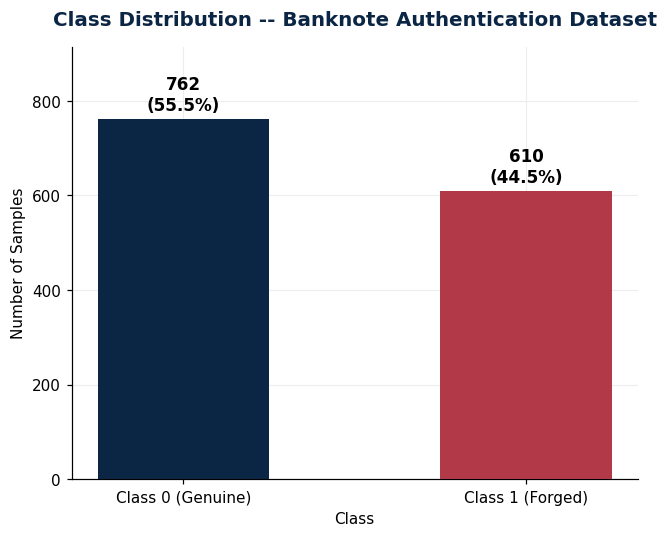

In [20]:
fig, ax = plt.subplots(figsize=(6, 5))
counts = df["class"].value_counts().sort_index()
bars = ax.bar([CLASS_LABELS[0], CLASS_LABELS[1]], counts.values, color=[NAVY, RED], width=0.5, zorder=3)
for b, v in zip(bars, counts.values):
    pct = 100 * v / len(df)
    ax.text(b.get_x() + b.get_width()/2, v + 10, f"{v}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=11, fontweight="bold")
ax.set_title("Class Distribution -- Banknote Authentication Dataset", fontsize=13, fontweight="bold", color=NAVY, pad=14)
ax.set_xlabel("Class")
ax.set_ylabel("Number of Samples")
ax.set_ylim(0, max(counts.values) * 1.2)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/01_class_distribution_bar.png", dpi=150)
plt.show()


### ۴.۲ Histogram هر چهار ویژگی به تفکیک کلاس

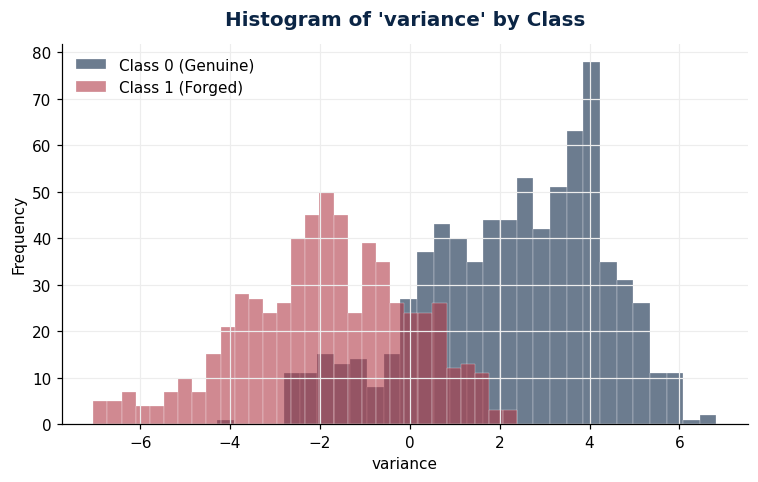

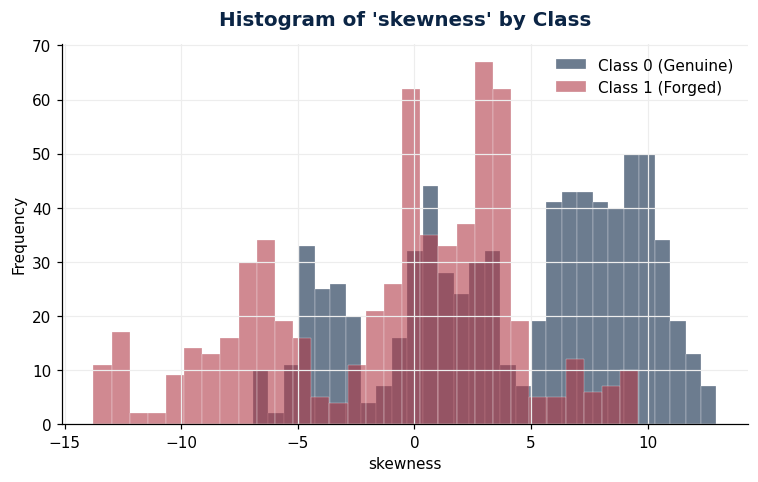

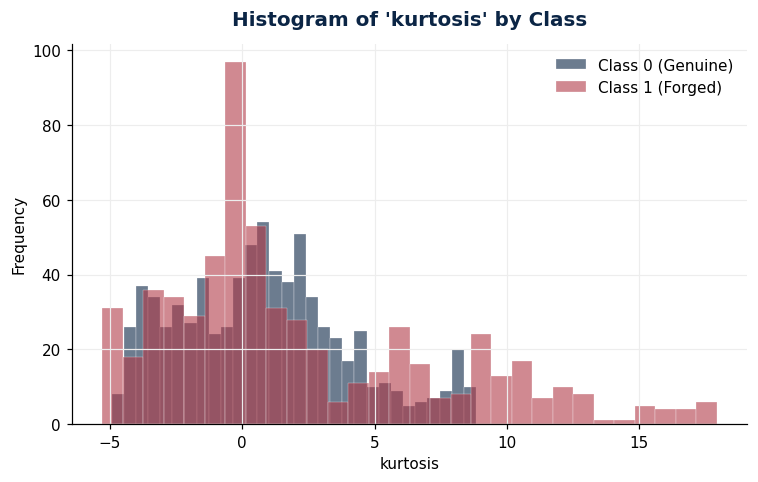

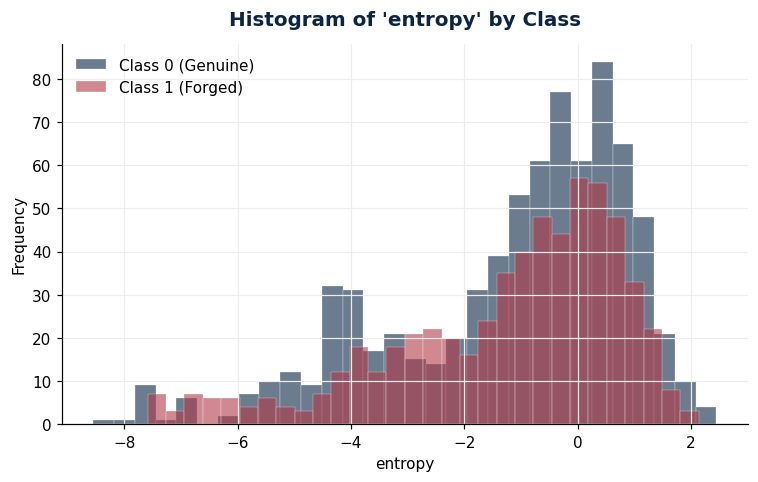

In [21]:
for i, f in enumerate(numeric_cols, start=1):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for cls in [0, 1]:
        sub = df[df["class"] == cls][f]
        ax.hist(sub, bins=30, alpha=0.6, color=CLASS_COLORS[cls], label=CLASS_LABELS[cls], edgecolor="white", linewidth=0.3)
    ax.set_title(f"Histogram of '{f}' by Class", fontsize=13, fontweight="bold", color=NAVY, pad=12)
    ax.set_xlabel(f)
    ax.set_ylabel("Frequency")
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/02_{i}_histogram_{f}.png", dpi=150)
    plt.show()


### ۴.۳ Boxplot هر چهار ویژگی (به تفکیک کلاس)

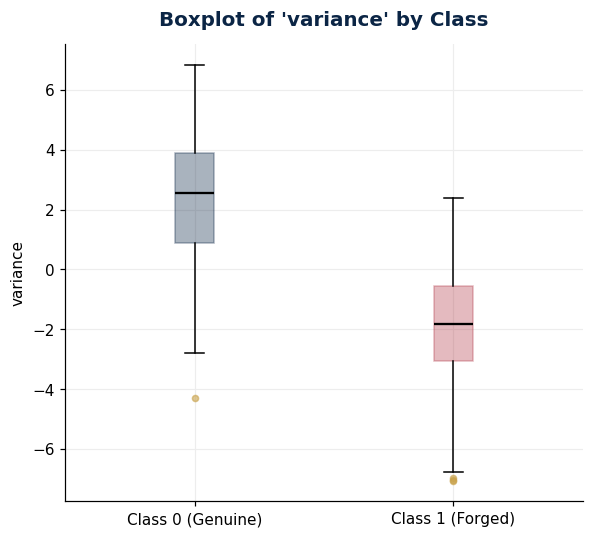

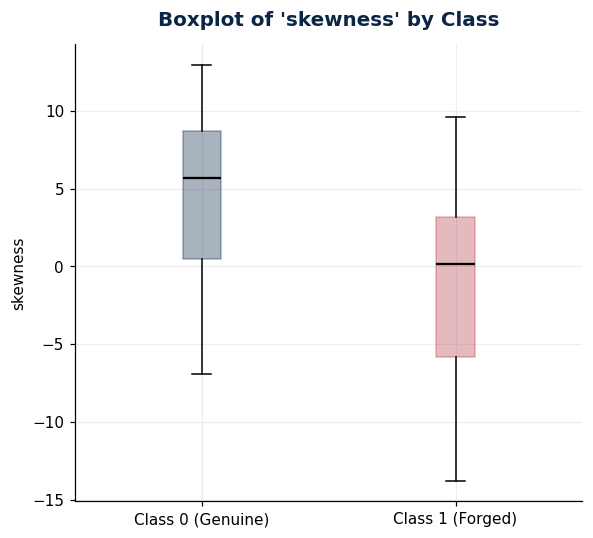

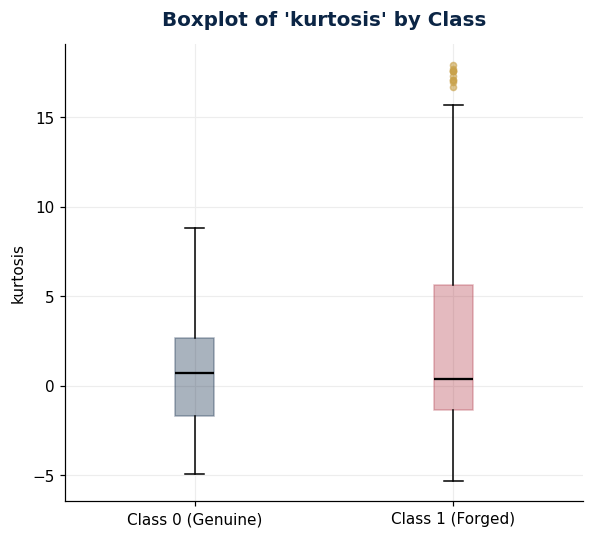

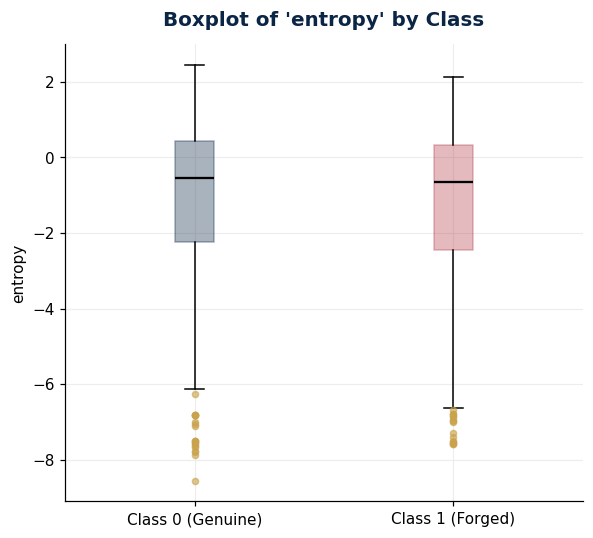

In [22]:
for i, f in enumerate(numeric_cols, start=1):
    fig, ax = plt.subplots(figsize=(5.5, 5))
    data = [df[df["class"] == 0][f], df[df["class"] == 1][f]]
    bp = ax.boxplot(data, labels=[CLASS_LABELS[0], CLASS_LABELS[1]], patch_artist=True,
                     medianprops=dict(color="black", linewidth=1.5),
                     flierprops=dict(marker="o", markersize=4, markerfacecolor=GOLD, markeredgecolor=GOLD, alpha=0.6))
    for patch, cls in zip(bp["boxes"], [0, 1]):
        patch.set_facecolor(CLASS_COLORS[cls]); patch.set_alpha(0.35); patch.set_edgecolor(CLASS_COLORS[cls])
    ax.set_title(f"Boxplot of '{f}' by Class", fontsize=13, fontweight="bold", color=NAVY, pad=12)
    ax.set_ylabel(f)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/03_{i}_boxplot_{f}.png", dpi=150)
    plt.show()


### ۴.۴ Scatter Plot برای دو جفت ویژگی (رنگ متفاوت برای هر کلاس)

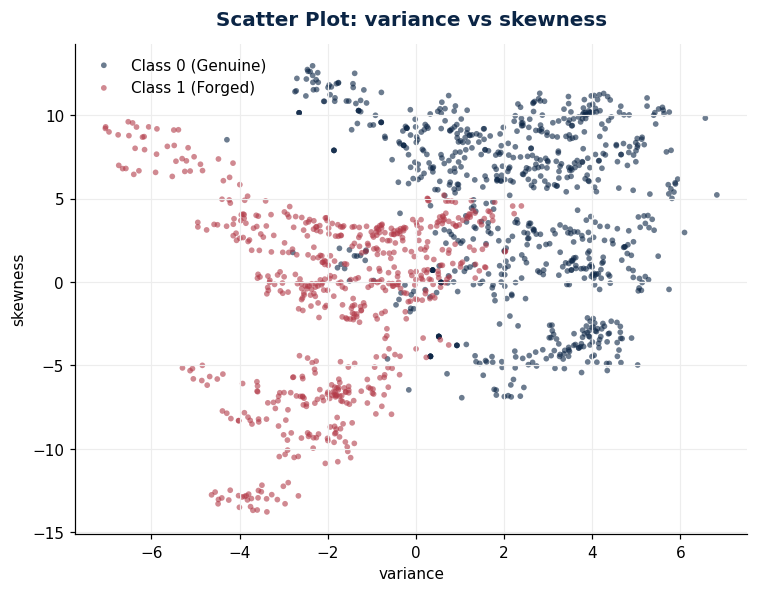

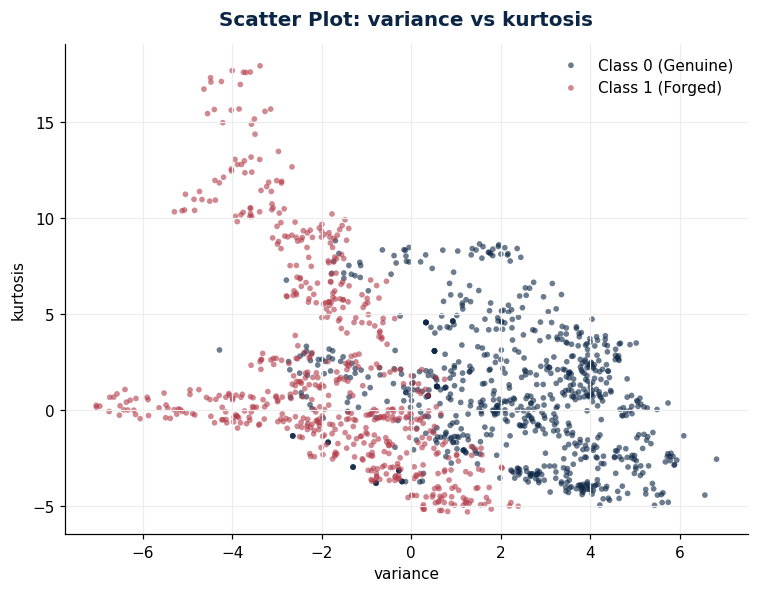

In [23]:
scatter_pairs = [("variance", "skewness"), ("variance", "kurtosis")]
for i, (fx, fy) in enumerate(scatter_pairs, start=1):
    fig, ax = plt.subplots(figsize=(7, 5.5))
    for cls in [0, 1]:
        sub = df[df["class"] == cls]
        ax.scatter(sub[fx], sub[fy], s=14, alpha=0.6, color=CLASS_COLORS[cls], label=CLASS_LABELS[cls], edgecolors="none")
    ax.set_title(f"Scatter Plot: {fx} vs {fy}", fontsize=13, fontweight="bold", color=NAVY, pad=12)
    ax.set_xlabel(fx)
    ax.set_ylabel(fy)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/04_{i}_scatter_{fx}_vs_{fy}.png", dpi=150)
    plt.show()


### ۴.۵ ماتریس همبستگی ویژگی‌ها

,variance,skewness,kurtosis,entropy,class
variance,1.000000,0.264026,-0.380850,0.276817,-0.724843
skewness,0.264026,1.000000,-0.786895,-0.526321,-0.444688
kurtosis,-0.380850,-0.786895,1.000000,0.318841,0.155883
entropy,0.276817,-0.526321,0.318841,1.000000,-0.023424
class,-0.724843,-0.444688,0.155883,-0.023424,1.000000


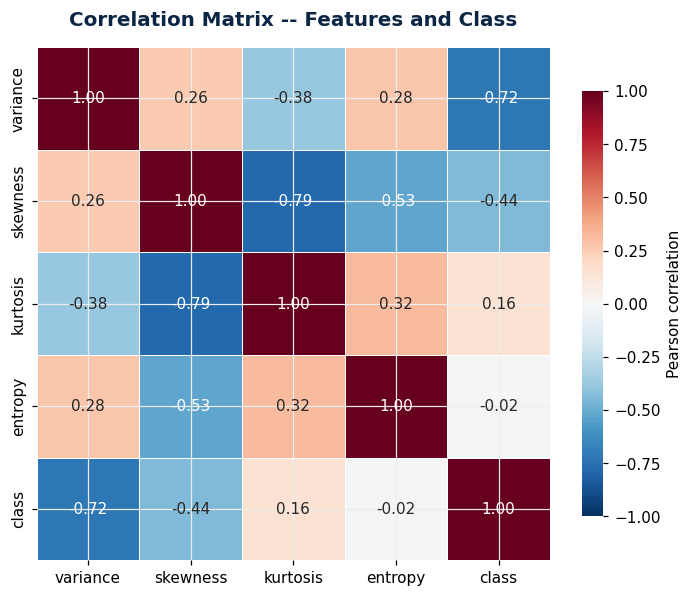

In [24]:
corr = df[numeric_cols + ["class"]].corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, linecolor="white", ax=ax,
            cbar_kws={"shrink": 0.8, "label": "Pearson correlation"})
ax.set_title("Correlation Matrix -- Features and Class", fontsize=13, fontweight="bold", color=NAVY, pad=14)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/05_correlation_heatmap.png", dpi=150)
plt.show()
corr


In [25]:
print("Correlation of each feature with the target class (sorted by |correlation|):")
corr_with_class = corr["class"].drop("class").sort_values(key=abs, ascending=False)
corr_with_class


Correlation of each feature with the target class (sorted by |correlation|):


variance   -0.724843
skewness   -0.444688
kurtosis    0.155883
entropy    -0.023424
Name: class, dtype: float64

## ۵. تفسیر نمودارها

**در Scatter Plot آیا مرز جدایی بین دو کلاس دیده می‌شود؟**
**تا حدودی (بله با هم‌پوشانی محدود).** در نمودار `variance vs skewness`، دو کلاس عمدتاً در دو ناحیه مجزا قرار می‌گیرند (کلاس ۱ عمدتاً در سمت `variance` منفی و کلاس ۰ عمدتاً در سمت `variance` مثبت)، اما یک نوار هم‌پوشانی حول `variance ≈ 0` تا `2` وجود دارد که دو کلاس در آن قابل تفکیک کامل نیستند. در `variance vs kurtosis` هم‌پوشانی کمی بیشتر دیده می‌شود.

**کدام ویژگی‌ها جدایی بهتری ایجاد می‌کنند؟**
بر اساس ضریب همبستگی هر ویژگی با کلاس هدف (`corr_with_class` در بالا)، **`variance` با همبستگی ≈ ۰.۷۲- قوی‌ترین ویژگی تفکیک‌کننده منفرد است**، و پس از آن `skewness` (≈ ۰.۴۴-) قرار دارد. `kurtosis` (≈ ۰.۱۶) و به‌ویژه `entropy` (≈ ۰.۰۲-، تقریباً بدون رابطه خطی با کلاس) ضعیف‌ترین قدرت تفکیک‌کنندگی منفرد را دارند. این نکته جالب توجه است: اگرچه `skewness` بیشترین اختلاف میانگین خام را بین دو کلاس داشت (سؤال ۱ در بخش ۳)، این `variance` است که در عمل بهترین مرز جداکننده را ایجاد می‌کند — زیرا پراکندگی (Std) بالای `skewness` باعث هم‌پوشانی بیشتر توزیع دو کلاس می‌شود.

**آیا توزیع کلاس‌ها متوازن است؟**
تقریباً بله. کلاس ۰ شامل ۷۶۲ نمونه (۵۵.۵٪) و کلاس ۱ شامل ۶۱۰ نمونه (۴۴.۵٪) است. این یک عدم توازن **خفیف** است (نسبت تقریبی ۵۵ به ۴۵)، نه یک عدم توازن شدید (مثل ۹۵ به ۵). بنابراین دقت (Accuracy) هنوز معیار نسبتاً معناداری خواهد بود، اما توصیه می‌شود در تقسیم داده از `stratify=df["class"]` استفاده شود (طبق خواسته پروژه) تا این نسبت در مجموعه‌های Train/Validation/Test نیز حفظ شود.
